(<Axes: >,
 (array([82352., 69386., 31848., 27764., 33469., 31434., 26493., 20650.,
         16939.,  5265.]),
  array([  0. ,  25.5,  51. ,  76.5, 102. , 127.5, 153. , 178.5, 204. ,
         229.5, 255. ]),
  <BarContainer object of 10 artists>))

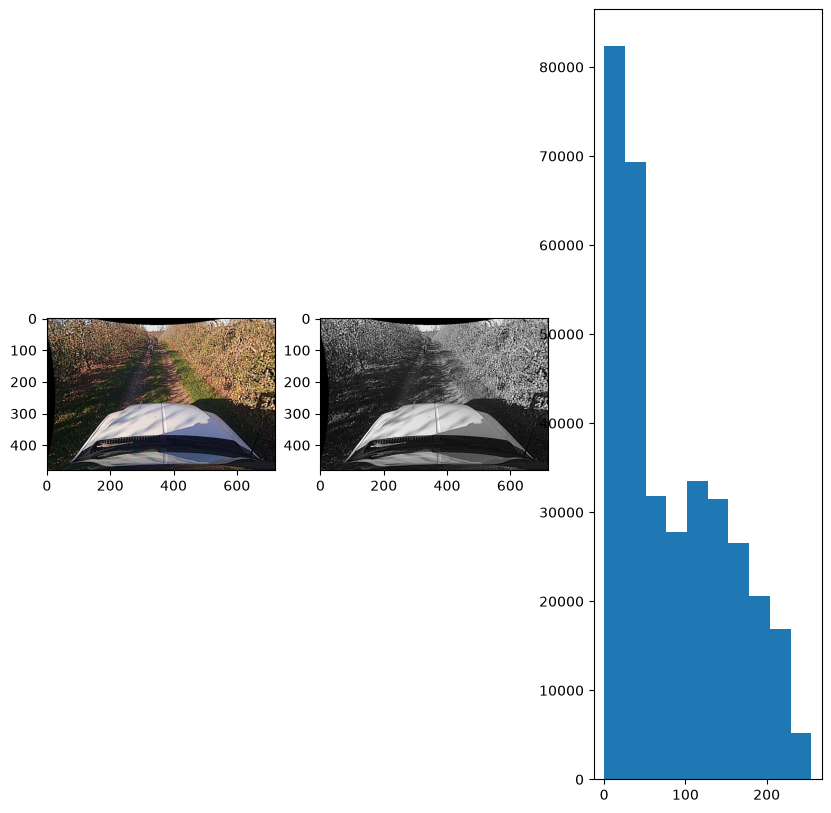

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
BASE_DIR='/media/dpaulino/31c12798-f2e4-45f8-9614-3dd2fec82907/agriImages/content/nrec/selected/images/train/'

image1=BASE_DIR+'Image_0_0_1447440969.257.png'
#image1=BASE_DIR+'Image_0_0_1447083652.066.png'
#image1=BASE_DIR+'Image_0_0_1447083654.066.png'
#image1=BASE_DIR+'Image_0_0_1447086544.902.png'
image1=BASE_DIR+'Image_0_0_1447086547.169.png'
image1=BASE_DIR+'Image_0_0_1447689038.248.png'
#image1=BASE_DIR+'Image_0_0_1447689939.060.png'
image1=BASE_DIR+'Image_0_0_1447702858.930.png'

img = cv2.imread(image1).astype("uint8")
#gray_image = cv2.imread(image1, cv2.IMREAD_GRAYSCALE)
gray_image = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
rgb_image = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

gray_image_g = cv2.GaussianBlur(gray_image,(43,43),0)
#ret, thresh_img = cv2.threshold(gray_image_g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

ret, thresh_img = cv2.threshold(gray_image_g, 80, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(10,10))
plt.subplot(1,3,1),plt.imshow(rgb_image)
plt.subplot(1,3,2),plt.imshow(gray_image,'gray')

hist = cv2.calcHist([gray_image], [0], None, [256], [0, 256])
plt.subplot(1,3,3),plt.hist(np.ravel(gray_image))





In [23]:
gray_image

array([[125, 124, 119, ..., 138,  89,  60],
       [141, 140, 128, ..., 171, 118,  94],
       [142, 152, 142, ..., 148,  41,  88],
       ...,
       [ 30,  24,  23, ...,  20,  26,  29],
       [ 30,  18,   0, ...,  15,  15,  17],
       [ 28,  29,  25, ...,  43,  26,  22]], shape=(480, 720), dtype=uint8)

(<Axes: >, <matplotlib.image.AxesImage at 0x731c825e3250>)

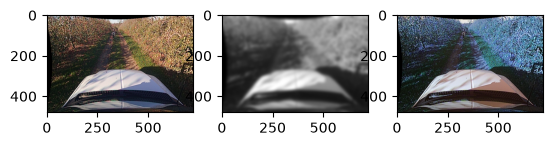

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
BASE_DIR='/media/dpaulino/31c12798-f2e4-45f8-9614-3dd2fec82907/agriImages/content/nrec/selected/images/train/'

image1=BASE_DIR+'Image_0_0_1447440969.257.png'
#image1=BASE_DIR+'Image_0_0_1447083652.066.png'
#image1=BASE_DIR+'Image_0_0_1447083654.066.png'
#image1=BASE_DIR+'Image_0_0_1447086544.902.png'
image1=BASE_DIR+'Image_0_0_1447086547.169.png'
#image1=BASE_DIR+'Image_0_0_1447689038.248.png'
#image1=BASE_DIR+'Image_0_0_1447689939.060.png'
image1=BASE_DIR+'Image_0_0_1447702858.930.png'

bgr_image = cv2.imread(image1).astype("uint8")
gray_image = cv2.imread(image1, cv2.IMREAD_GRAYSCALE)
# 2. Converte o espaço de cor de BGR para RGB
rgb_image = cv2.cvtColor(bgr_image, cv2.COLOR_BGR2RGB)

gray_image_g = cv2.GaussianBlur(gray_image,(43,43),0)
#ret, thresh_img = cv2.threshold(gray_image_g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

ret, thresh_img = cv2.threshold(gray_image_g, 80, 255, cv2.THRESH_BINARY)

plt.subplot(1,3,1),plt.imshow(rgb_image)
plt.subplot(1,3,2),plt.imshow(gray_image_g,'gray')
plt.subplot(1,3,3),plt.imshow(bgr_image)


/home/dpaulino/anaconda3/envs/project/lib/python3.13/site-packages/vnoise/__init__.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


INFO - creating occlusion instance of fogEffect with factor 0.1
INFO - creating occlusion instance of fogEffect with factor 0.2
INFO - creating occlusion instance of fogEffect with factor 0.3


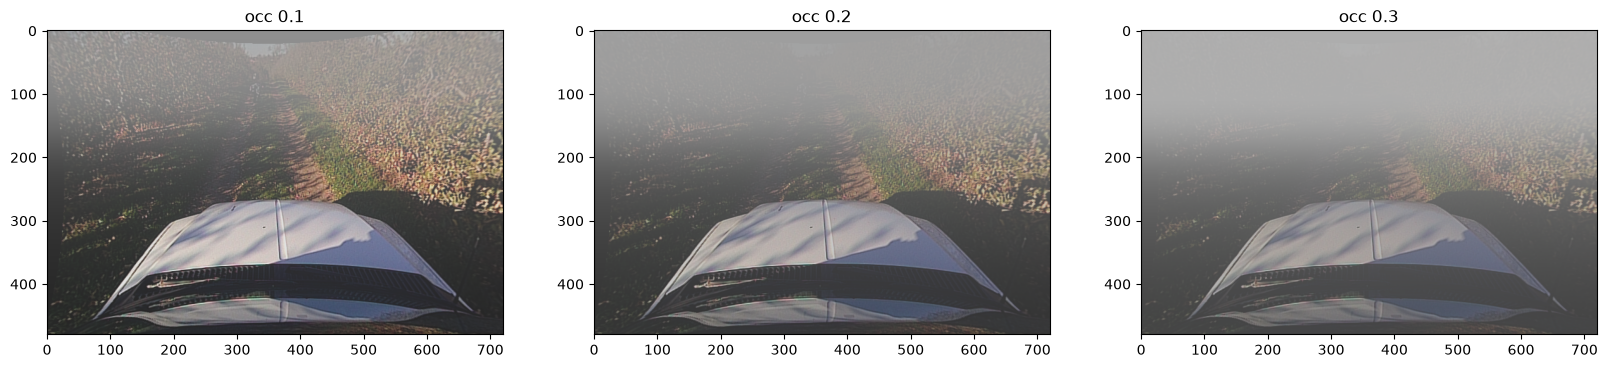

In [3]:
from nrec_utils.occlusions.fog_occlusion import fake_depth_map,Fog
fig = plt.figure(figsize=(20, 20))

for i,occ_factor in enumerate([0.1,0.2,0.3]):
    fog_occ=Fog(occ_factor)
    occ_img = fog_occ.generate_occluded_image(image=bgr_image, bboxs=[],seed=156)
    plt.subplot(1,3,(i+1))
    plt.title(f'occ {occ_factor}')
    plt.imshow(cv2.cvtColor(occ_img, cv2.COLOR_BGR2RGB))

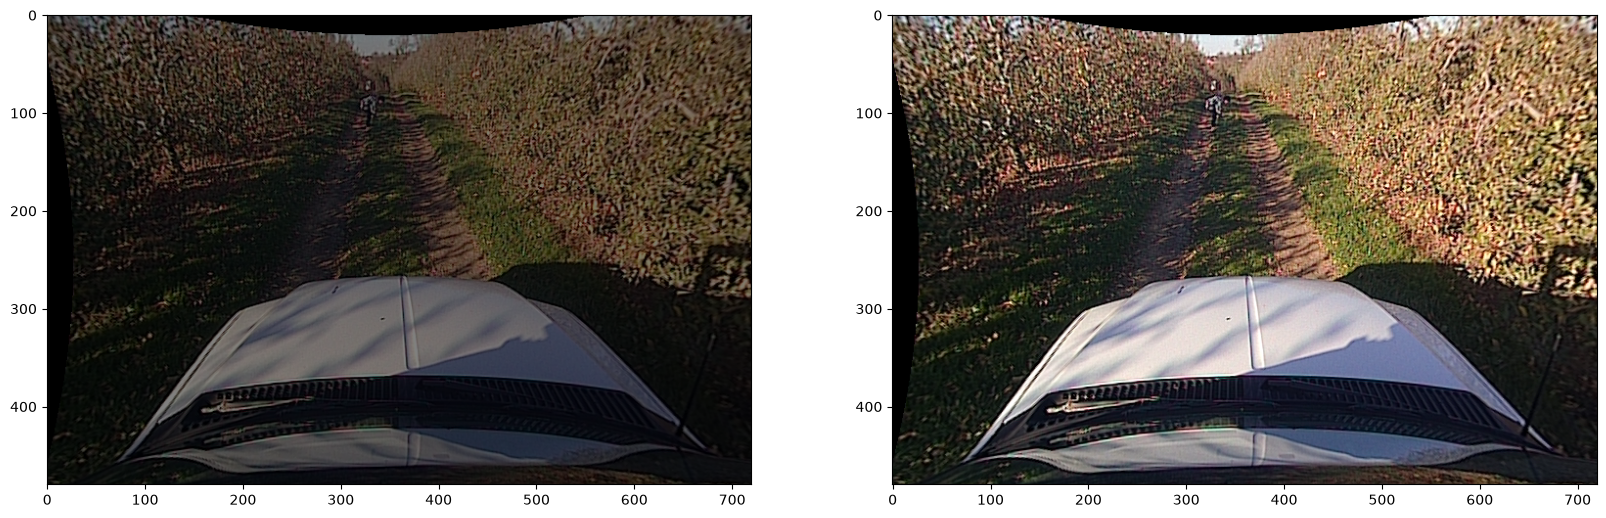

In [8]:
from nrec_utils.occlusions.fog_occlusion import adjust_brightness_bisection

img_dark_bisection=adjust_brightness_bisection(bgr_image,0.5,10)

fig = plt.figure(figsize=(20, 10))

plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img_dark_bisection, cv2.COLOR_BGR2RGB))

plt.subplot(1,2,2)
plt.imshow(rgb_image)
plt.show()

INFO - creating occlusion instance of smoke with factor 0.2


array([[0.05      , 0.05      , 0.05      , ..., 0.05      , 0.05      ,
        0.05      ],
       [0.05      , 0.05      , 0.05      , ..., 0.05      , 0.05      ,
        0.05      ],
       [0.05      , 0.05      , 0.05      , ..., 0.05      , 0.05      ,
        0.05      ],
       ...,
       [0.93175667, 0.93175667, 0.93175667, ..., 0.93175667, 0.93175667,
        0.93175667],
       [0.93176657, 0.93176657, 0.93176657, ..., 0.93176657, 0.93176657,
        0.93176657],
       [0.93177152, 0.93177152, 0.93177152, ..., 0.93177152, 0.93177152,
        0.93177152]], shape=(480, 720))

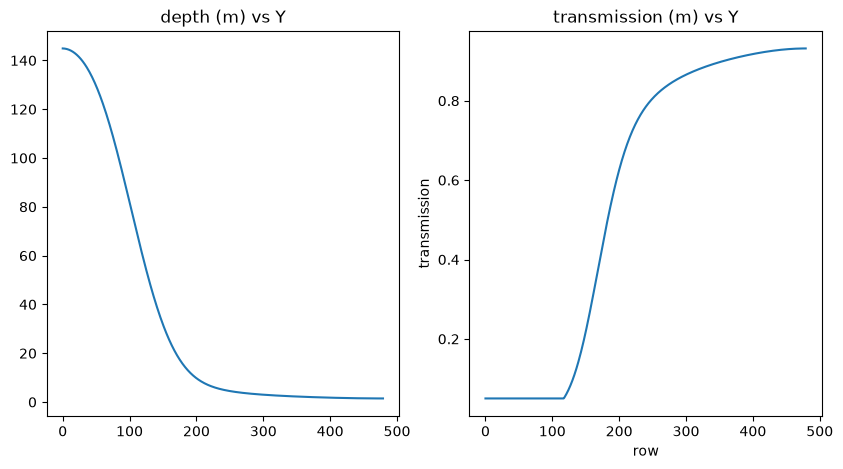

In [12]:
# transmission curve
from nrec_utils.occlusions.smoke_occlusion import fake_depth_map,Smoke

depth = fake_depth_map(rgb_image,z_max=150,sigma_frac=0.1)
depth[:,1]
y = range(0,len(depth[:,1]))
fig = plt.figure(figsize=(10, 5))
plt.subplot(1,2,1)
plt.plot(y,depth[:,1])
plt.title('depth (m) vs Y')

smoke = Smoke(0.2)
beta=0.2*0.06*4
transmission = np.clip(smoke.calculate_transmission_gaussian(beta=beta,depth=depth,density=1.0)+0.00,0.05,1.0)
transmission[:,1]
plt.subplot(1,2,2)
plt.plot(y,transmission[:,1])
plt.xlabel('row')
plt.ylabel('transmission')
plt.title('transmission (m) vs Y')
transmission